# Brake & Burst — Combine to NFL performance

Self-contained reproducible analysis. **Synthetic results are not NFL evidence.** Attach the licensed competition dataset in Kaggle after accepting the rules. No local package imports, authentication, downloads or external files are required. The fallback creates synthetic schema-matched data with planted signal. Code: MIT; competition data: CC BY-NC 4.0. Publish this notebook publicly and attach its URL to the writeup only after a real-data run and review.

## Data

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

SCHEMA = {
    'players': 'nfl_id display_name draft_year nfl_position birth_date college_name college_conference draft_round draft_pick_within_round draft_overall_pick',
    'combine_results': 'draft_year nfl_id combine_position combine_height combine_weight hand_size arm_length wing_span ten_yd_split forty vertical broad_jump three_cone short_shuttle bench_reps ngs_athleticism_score ngs_college_production_score ngs_final_score',
    'combine_tracking': 'draft_year event_id nfl_id entity_type time drill_type drill_name attempt x y s a dis dir',
    'player_career_successes': 'nfl_id career_offensive_snaps career_defensive_snaps career_special_teams_snaps career_games_active career_games_started ap_all_pro_1st_team ap_all_pro_2nd_team pro_bowl_original_ballot',
    'games': 'game_id game_key season season_type week home_team_abbr visitor_team_abbr',
    'player_play': 'game_id play_id team_abbr nfl_id lined_up_position play_description quarter down yards_to_go possession_team yardline_side yardline_number game_clock pre_snap_home_score pre_snap_visitor_score play_direction pre_snap_home_team_win_probability pre_snap_visitor_team_win_probability home_team_win_probability_added visitor_team_win_probility_added expected_points_added expected_points offense_formation receiver_alignment pass_result pass_length play_nullified_by_penalty penalty_yards pre_penalty_yards_gained yards_gained team_coverage_man_zone team_coverage_type in_motion_at_ball_snap target rec_yards rush_yards yards_after_catch fumble fumble_lost route_ran separation_at_pass_forward cushion expected_yards_after_catch dropback_duration extended_sack_allowed pass_rushers_encountered peak_pressure_probability_allowed pressure_allowed sack_allowed time_to_pressure_allowed blitzing player_get_off sack tackle assist caused_forced_fumble recovered_fumble tackle_for_loss time_to_pressure time_to_qb_hurry coverage_assignment coverage_assignment_at_snap quick_pressure unblocked_pressure',
    'game_tracking': 'game_id play_id nfl_id time x y s a dis o dir event',
}

def load_table(root, name, **kwargs):
    return pd.read_csv(Path(root) / (name + '.csv'), **kwargs)

def regular_plays(root):
    games = load_table(root, 'games')
    plays = load_table(root, 'player_play')
    return plays.merge(games.loc[games.season_type.eq('REG'), ['game_id', 'season']], on='game_id').query("play_nullified_by_penalty != 'Y'")


## Synthetic

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd

def trajectory(retention, speed=7., cut=True, noise=0.):
    t = np.arange(51 if cut else int(np.ceil((40/speed+1.1)*10))+1) / 10
    if cut:
        s = speed * (1 - (1-retention)*np.maximum(0, 1-abs(t-2)/.8))
        direction = 90 * np.clip((t-1.7)/.6, 0, 1)
    else:
        s = speed * (1-np.exp(-t))
        direction = np.zeros(len(t))
        finish=np.flatnonzero(np.cumsum(s*.1)>=40)
        if len(finish):
            end=finish[0]+1
            t=t[:end]; s=s[:end]; direction=direction[:end]
    rad = np.deg2rad(direction)
    return pd.DataFrame(dict(time=pd.date_range('2025-03-01', periods=len(t), freq='100ms').astype(str),
        x=30+np.cumsum(s*np.sin(rad)*.1), y=5+np.cumsum(s*np.cos(rad)*.1),
        s=s, a=np.gradient(s,.1), dis=s*.1, dir=direction))

def generate(root, seed=2027, n=150):
    root = Path(root); root.mkdir(parents=True, exist_ok=True)
    rng = np.random.default_rng(seed)
    players=[]; results=[]; career=[]; combine=[]; plays=[]; games=[]
    tracking={y:[] for y in [2023,2024,2025]}
    for i in range(n):
        pid=55000+i; year=2023+i%3; pos=['WR','TE','RB','CB','SS'][i%5]
        agility=rng.normal(); fast=rng.normal(); talent=.6*agility+.5*fast+rng.normal(0,.9)
        pick=int(np.clip(140-30*talent+rng.normal(0,55),1,259))
        players.append(dict(nfl_id=pid, display_name=f'Synthetic Prospect {i:03}', draft_year=year,
            nfl_position=pos,birth_date='2001-02-01',college_name='Synthetic University',college_conference='Synthetic',
            draft_round=min(7,1+pick//37) if i%11 else np.nan,draft_pick_within_round=1+pick%32 if i%11 else np.nan,draft_overall_pick=pick if i%11 else np.nan))
        results.append(dict(nfl_id=pid,draft_year=year,combine_position=pos,combine_height=rng.normal(74,2),combine_weight=int(rng.normal(235 if pos=='TE' else 205,12)),hand_size=9.5,arm_length=32.,wing_span=77.,
            ten_yd_split=1.6-.04*fast+rng.normal(0,.04),forty=4.6-.1*fast+rng.normal(0,.08),vertical=34+2*fast+rng.normal(),broad_jump=120+4*fast+rng.normal(0,3),three_cone=7-.05*agility+rng.normal(0,.14) if i%9 else np.nan,short_shuttle=4.3-.03*agility+rng.normal(0,.1),bench_reps=18.,ngs_athleticism_score=60,ngs_college_production_score=65.,ngs_final_score=65.))
        active=(2026-year)*15; ratio=1/(1+np.exp(-(.6*talent+rng.normal(0,.6))))
        career.append(dict(nfl_id=pid,career_offensive_snaps=int(active*35*ratio) if pos in ['WR','TE','RB'] else 0,career_defensive_snaps=int(active*35*ratio) if pos in ['CB','SS'] else 0,career_special_teams_snaps=80,career_games_active=active,career_games_started=int(active*ratio),ap_all_pro_1st_team=0,ap_all_pro_2nd_team=0,pro_bowl_original_ballot=0))
        for j,drill in enumerate(['THREE_CONE_DRILL','SHORT_SHUTTLE','SKILL_DRILLS_'+('DB' if pos in ['CB','SS'] else pos),'FORTY_YARD_DASH']):
            z=trajectory(np.clip(.56+.065*agility+rng.normal(0,.025),.3,.8),speed=(10.7 if j==3 else 7.5)+.3*fast,cut=j!=3)
            z.time=z.time.str.replace('2025-',f'{year}-',regex=False)
            z=z.assign(nfl_id=pid,draft_year=year,event_id=f'{pid}_{j}',entity_type='PLAYER',drill_type=drill,drill_name='FORTY_YARD_DASH' if j==3 else 'SLOT_STRIKE_ROUTE_LEFT',attempt=1)
            combine.append(z)
        for j in range(18):
            season=year+j%(2026-year); gid=season*1000000+91000+i+(30000 if j==17 else 0); playid=j+1
            games.append(dict(game_id=gid,game_key=gid,season=season,season_type='POST' if j==17 else 'REG',week=1+j%18,home_team_abbr='KC',visitor_team_abbr='BUF'))
            target=bool(rng.random()<.65); route=rng.choice(['OUT','SLANT','POST']); cov=rng.choice(['MAN_COVERAGE','ZONE_COVERAGE']); cushion=rng.uniform(3,9)
            sep=max(.1,2.3+.28*agility+.12*fast+.10*cushion+.25*(cov=='ZONE_COVERAGE')+.15*(route=='POST')+rng.normal(0,.85))
            row=dict.fromkeys(SCHEMA['player_play'].split(),0.)
            row.update(game_id=gid,play_id=playid,nfl_id=pid,team_abbr='KC',lined_up_position=pos,play_description='Synthetic pass',quarter=1,down=1+j%3,yards_to_go=10,possession_team='KC',yardline_side='KC',yardline_number=25,game_clock='12:00',pre_snap_home_score=0,pre_snap_visitor_score=0,play_direction='right',pre_snap_home_team_win_probability=.5,pre_snap_visitor_team_win_probability=.5,offense_formation='SHOTGUN',receiver_alignment='2x2',pass_result='C',pass_length=8.,play_nullified_by_penalty='N',penalty_yards=np.nan,pre_penalty_yards_gained=8,yards_gained=8,team_coverage_man_zone=cov,team_coverage_type='COVER_1' if cov=='MAN_COVERAGE' else 'COVER_3',in_motion_at_ball_snap=False,target=target,rec_yards=max(0,rng.normal(8+talent,5)) if target else 0.,rush_yards=np.nan,yards_after_catch=3.,route_ran=route if pos in ['WR','TE','RB'] else np.nan,separation_at_pass_forward=sep if target and pos in ['WR','TE','RB'] else np.nan,cushion=cushion,expected_yards_after_catch=3.,expected_points_added=rng.normal(.15*talent,.7),expected_points=1.,dropback_duration=5.,pressure_allowed=False,blitzing=False,coverage_assignment='MAN',coverage_assignment_at_snap='MAN',tackle=float(rng.random()<.15))
            plays.append(row)
            z=trajectory(np.clip(.55+.055*agility+rng.normal(0,.06),.25,.85),speed=7+.3*fast)
            z.time=z.time.str.replace('2025-03-01',f'{season}-09-10',regex=False)
            z=z.assign(game_id=gid,play_id=playid,nfl_id=pid,o=z.dir,event='')
            z.loc[0,'event']='ball_snap'; z.loc[50,'event']='pass_forward'
            tracking[season].append(z)
    tables=dict(players=pd.DataFrame(players),combine_results=pd.DataFrame(results),player_career_successes=pd.DataFrame(career),combine_tracking=pd.concat(combine),player_play=pd.DataFrame(plays),games=pd.DataFrame(games).drop_duplicates('game_id'))
    for name,df in tables.items(): df[SCHEMA[name].split()].to_csv(root/f'{name}.csv',index=False)
    for year,parts in tracking.items(): pd.concat(parts)[SCHEMA['game_tracking'].split()].to_csv(root/f'game_tracking_{year}.csv',index=False)
    (root/'SYNTHETIC.txt').write_text(f'Artificial validation fixture; seed={seed}; not NFL observations.\n')
    return root


## Combine Features

In [3]:
import numpy as np
import pandas as pd
from scipy.signal import find_peaks

CUT_METRICS=['entry_speed','min_speed','exit_speed','peak_deceleration','recovery_time','csr']

def cuts(frames):
    f=frames.sort_values('time').reset_index(drop=True)
    if len(f)<21: return pd.DataFrame(columns=CUT_METRICS)
    s=f['s'].to_numpy(); direction=f['dir'].to_numpy()
    times=(pd.to_datetime(f.time)-pd.to_datetime(f.time.iloc[0])).dt.total_seconds().to_numpy()
    candidates,_=find_peaks(-s,distance=10,prominence=.25)
    rows=[]
    for k in candidates:
        if k<5 or k+10>=len(f): continue
        delta=abs((direction[k+3]-direction[k-3]+180)%360-180)
        entry=float(np.median(s[k-5:k-2]))
        if delta<45 or entry<2: continue
        recovery=np.flatnonzero(s[k+1:]>=.8*entry)
        rows.append(dict(entry_speed=entry,min_speed=s[k],exit_speed=s[k+10],
            peak_deceleration=max(0,-np.min(np.gradient(s[k-5:k+1],times[k-5:k+1]))),
            recovery_time=times[k+1+recovery[0]]-times[k] if len(recovery) else np.nan,csr=s[k]/entry,
            cut_frame=k,turn_degrees=delta))
    return pd.DataFrame(rows)

def aggregate_cuts(table, prefix):
    if table.empty: return pd.DataFrame(columns=['nfl_id'])
    grouped=table.groupby('nfl_id')[CUT_METRICS]
    med=grouped.median().add_prefix(prefix)
    iqr=(grouped.quantile(.75)-grouped.quantile(.25)).add_prefix(prefix).add_suffix('_iqr')
    return med.join(iqr).join(table.groupby('nfl_id').size().rename(prefix+'cut_count')).reset_index()

def combine_features(root):
    f=load_table(root,'combine_tracking'); f=f.loc[f.entity_type.eq('PLAYER') & f.nfl_id.notna()]
    parts=[]; sprints=[]
    allowed=['THREE_CONE_DRILL','SHORT_SHUTTLE','SKILL_DRILLS_WR','SKILL_DRILLS_TE','SKILL_DRILLS_DB']
    for (pid,event),g in f.groupby(['nfl_id','event_id']):
        drill=g.drill_type.iloc[0]
        if drill in allowed:
            # Position skill drills must describe a route or transition, not catching-only drills.
            if drill.startswith('SKILL') and not g.drill_name.str.contains('ROUTE|TRANSITION|PEDAL',case=False,regex=True).any(): continue
            c=cuts(g)
            if len(c): parts.append(c.assign(nfl_id=pid,event_id=event))
        if drill=='FORTY_YARD_DASH':
            g=g.sort_values('time'); speed=g.s.to_numpy(); t=pd.to_datetime(g.time)
            sprints.append(dict(nfl_id=pid,sprint_max_speed=speed.max(),sprint_time90=(t.iloc[np.flatnonzero(speed>=.9*speed.max())[0]]-t.iloc[0]).total_seconds(),sprint_peak_accel=np.max(np.gradient(speed,.1))))
    cut_table=pd.concat(parts,ignore_index=True) if parts else pd.DataFrame()
    agg=aggregate_cuts(cut_table,'combine_')
    if sprints: agg=agg.merge(pd.DataFrame(sprints).groupby('nfl_id').median().reset_index(),on='nfl_id',how='outer')
    return agg,cut_table


## Game Features

In [4]:
from pathlib import Path
import tempfile
import numpy as np
import pandas as pd

def game_features(root, chunksize=50000):
    plays=regular_plays(root)
    eligible=plays.loc[plays.route_ran.notna() | plays.lined_up_position.isin(['CB','DB','SS','FS'])]
    wanted=set(map(tuple,eligible[['game_id','play_id','nfl_id']].to_numpy()))
    parts=[]
    # Hash partition by player keeps entire plays together even for interleaved or unsorted CSVs.
    # Only one partition is loaded at a time; temporary filtered shards are removed on exit.
    with tempfile.TemporaryDirectory(prefix='bdb27-shards-',dir=Path.cwd()) as temp:
        for path in sorted(Path(root).glob('game_tracking_*.csv')):
            for chunk in pd.read_csv(path,usecols=SCHEMA['game_tracking'].split(),chunksize=chunksize):
                mask=[key in wanted for key in chunk[['game_id','play_id','nfl_id']].itertuples(index=False,name=None)]
                chunk=chunk.loc[mask]
                for bucket,g in chunk.groupby(chunk.nfl_id%32):
                    out=Path(temp)/f'{int(bucket)}.csv'
                    g.to_csv(out,mode='a',header=not out.exists(),index=False)
        for path in Path(temp).glob('*.csv'):
            shard=pd.read_csv(path)
            for (gid,play,pid),g in shard.groupby(['game_id','play_id','nfl_id']):
                g=g.sort_values('time').reset_index(drop=True)
                snap=g.index[g.event.eq('ball_snap')]; throw=g.index[g.event.eq('pass_forward')]
                if not len(snap) or not len(throw) or throw[-1]<=snap[0]: continue
                c=cuts(g.iloc[snap[0]:throw[-1]+1])
                if len(c): parts.append(c.assign(nfl_id=pid,game_id=gid,play_id=play))
    table=pd.concat(parts,ignore_index=True) if parts else pd.DataFrame()
    return aggregate_cuts(table,'game_'),plays,table

def exposure_outcomes(plays,career):
    rows=[]
    for pid,g in plays.groupby('nfl_id'):
        routes=g.route_ran.notna(); targets=g.target.eq(True) & routes
        seasons=g.season.nunique()
        active=career.loc[career.nfl_id.eq(pid)]
        if active.empty: continue
        c=active.iloc[0]; ratio=c.career_games_started/max(1,c.career_games_active)
        rows.append(dict(nfl_id=pid,route_count=int(routes.sum()),target_count=int(targets.sum()),
            separation=g.loc[targets,'separation_at_pass_forward'].mean(),
            yards_per_route=g.loc[routes,'rec_yards'].fillna(0).sum()/max(1,routes.sum()),
            target_epa=g.loc[targets,'expected_points_added'].mean(),tackles_per_snap=g.tackle.sum()/len(g),
            reg_snaps_per_season=len(g)/seasons,
            # 17 games x 65 team snaps is explicitly an opportunity proxy, not true team snap share.
            snap_share_proxy=(len(g)/seasons)/(17*65),start_ratio=ratio,starter=int(ratio>=.5)))
    return pd.DataFrame(rows)


## Modelling

In [5]:
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import GradientBoostingRegressor, GradientBoostingClassifier
from sklearn.model_selection import LeaveOneGroupOut, RepeatedStratifiedKFold
from sklearn.metrics import r2_score, mean_absolute_error, roc_auc_score, brier_score_loss
from sklearn.inspection import permutation_importance

BASE=['forty','ten_yd_split','three_cone','short_shuttle','vertical','broad_jump','combine_height','combine_weight','nfl_position']
CONTEXT=['route_ran','team_coverage_man_zone','cushion','down','yards_to_go']

def estimator(columns, family='ridge', classification=False):
    cat=[x for x in columns if x in ['nfl_position','route_ran','team_coverage_man_zone']]
    num=[x for x in columns if x not in cat]
    transform=ColumnTransformer([
        ('numeric',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),num),
        ('category',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('encode',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),cat)])
    model=(LogisticRegression(C=.1,max_iter=1000) if classification else Ridge(alpha=20)) if family=='ridge' else (GradientBoostingClassifier(n_estimators=45,max_depth=2,min_samples_leaf=8,random_state=2027) if classification else GradientBoostingRegressor(n_estimators=45,max_depth=2,min_samples_leaf=8,random_state=2027))
    return Pipeline([('preprocess',transform),('model',model)])

def fold_outcome(players,plays,train_ids):
    p=plays.loc[plays.target.eq(True) & plays.nfl_id.isin(players.nfl_id) & plays.separation_at_pass_forward.notna()].copy()
    train=p.nfl_id.isin(train_ids)
    if train.sum()<5: raise ValueError('Too few training targets for context adjustment')
    context=estimator(CONTEXT)
    context.fit(p.loc[train,CONTEXT],p.loc[train,'separation_at_pass_forward'])
    p['residual']=p.separation_at_pass_forward-context.predict(p[CONTEXT])
    p=p.merge(players[['nfl_id','nfl_position']],on='nfl_id')
    train=p.nfl_id.isin(train_ids)
    prior=p.loc[train].groupby('nfl_position').residual.mean()
    stats=p.groupby('nfl_id').residual.agg(['sum','count'])
    joined=players[['nfl_id','nfl_position']].merge(stats,on='nfl_id',how='left').fillna({'sum':0,'count':0})
    joined['outcome']=(joined['sum']+10*joined.nfl_position.map(prior).fillna(0))/(joined['count']+10)
    return joined.set_index('nfl_id').outcome.reindex(players.nfl_id).to_numpy()

def scores(y,p,classification=False):
    if classification:
        return dict(auc=float(roc_auc_score(y,p)) if len(np.unique(y))>1 else np.nan,brier=float(brier_score_loss(y,p)))
    return dict(r2=float(r2_score(y,p)),spearman=float(spearmanr(y,p).statistic),mae=float(mean_absolute_error(y,p)))

def evaluate(frame,plays):
    df=frame.loc[frame.nfl_position.isin(['WR','TE']) & frame.target_count.ge(3)].reset_index(drop=True)
    if len(df)<20: raise ValueError('Need at least 20 WR/TE players with >=3 targets')
    tracking=[c for c in df if c.startswith(('combine_','sprint_')) and c!='combine_position' and c not in BASE]
    # No NFL outcomes or draft class are permitted predictors.
    variants={'A':BASE,'B':BASE+tracking,'A_draft':BASE+['draft_overall_pick'],'B_draft':BASE+['draft_overall_pick']+tracking}
    df['draft_overall_pick']=df.draft_overall_pick.fillna(260)
    splits={'draft_class':list(LeaveOneGroupOut().split(df,groups=df.draft_year)),
        'repeated_stratified':list(RepeatedStratifiedKFold(n_splits=3,n_repeats=2,random_state=2027).split(df,df.starter))}
    rows=[]; predictions=[]; importances=[]; audits=[]
    for validation,folds in splits.items():
        for fold,(tr,te) in enumerate(folds):
            y=fold_outcome(df,plays,set(df.iloc[tr].nfl_id))
            audits.append(dict(validation=validation,fold=fold,train_ids=df.iloc[tr].nfl_id.tolist(),test_ids=df.iloc[te].nfl_id.tolist()))
            for family in ['ridge','gradient_boosting']:
                for name,cols in variants.items():
                    for classification in [False,True]:
                        target=df.starter.to_numpy() if classification else y
                        model=estimator(cols,family,classification)
                        model.fit(df.iloc[tr][cols],target[tr])
                        pred=model.predict_proba(df.iloc[te][cols])[:,1] if classification else model.predict(df.iloc[te][cols])
                        rows.append(dict(validation=validation,fold=fold,family=family,variant=name,task='starter' if classification else 'separation',**scores(target[te],pred,classification)))
                        for j,idx in enumerate(te): predictions.append(dict(validation=validation,fold=fold,family=family,variant=name,task='starter' if classification else 'separation',nfl_id=int(df.nfl_id.iloc[idx]),truth=float(target[idx]),prediction=float(pred[j])))
                        if validation=='draft_class' and name=='B' and family=='ridge' and not classification:
                            imp=permutation_importance(model,df.iloc[te][cols],target[te],n_repeats=5,random_state=2027,scoring='neg_mean_absolute_error')
                            importances.extend(dict(feature=c,importance=float(v),fold=fold) for c,v in zip(cols,imp.importances_mean))
    metrics=pd.DataFrame(rows); pred=pd.DataFrame(predictions)
    paired=pred.query("validation == 'draft_class' and family == 'ridge' and task == 'separation' and variant in ['A','B']").pivot(index='nfl_id',columns='variant',values='prediction')
    truth=pred.query("validation == 'draft_class' and family == 'ridge' and task == 'separation' and variant == 'A'").set_index('nfl_id').truth.reindex(paired.index).to_numpy()
    rng=np.random.default_rng(2027); deltas=[]
    for _ in range(500):
        idx=rng.integers(0,len(truth),len(truth)); yy=truth[idx]
        deltas.append([r2_score(yy,paired.B.to_numpy()[idx])-r2_score(yy,paired.A.to_numpy()[idx]),mean_absolute_error(yy,paired.B.to_numpy()[idx])-mean_absolute_error(yy,paired.A.to_numpy()[idx])])
    ci=np.quantile(deltas,[.025,.975],axis=0)
    summary={name:scores(truth,paired[name]) for name in ['A','B']}
    summary.update(r2_improvement_ci=ci[:,0].tolist(),mae_difference_ci=ci[:,1].tolist(),n_players=len(df))
    # Draft expectation is also evaluated out of class, never fit on these players' outcomes.
    expectation=np.zeros(len(df))
    for tr,te in splits['draft_class']:
        y=fold_outcome(df,plays,set(df.iloc[tr].nfl_id))
        model=estimator(['draft_overall_pick','nfl_position']); model.fit(df.iloc[tr][['draft_overall_pick','nfl_position']],y[tr])
        expectation[te]=model.predict(df.iloc[te][['draft_overall_pick','nfl_position']])
    talent=df[['nfl_id','display_name','nfl_position','draft_year','draft_overall_pick','target_count']].copy()
    talent['tracking_prediction']=paired.B.reindex(df.nfl_id).to_numpy(); talent['draft_expectation']=expectation
    talent['surplus']=talent.tracking_prediction-talent.draft_expectation
    return metrics,pred,pd.DataFrame(importances),talent,summary,audits


## Plotting

In [6]:
from pathlib import Path
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

BLUE='#0072B2'; ORANGE='#D55E00'; GREEN='#009E73'

def figures(root,frame,trace,importance,summary):
    out=Path(root); out.mkdir(exist_ok=True)
    plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':120,
        'axes.prop_cycle':plt.cycler(color=[BLUE,ORANGE,GREEN,'#CC79A7','#E69F00'])})
    def save(name):
        plt.tight_layout(); plt.savefig(out/name,bbox_inches='tight'); plt.close()
    c=cuts(trace).iloc[0]; k=int(c.cut_frame); t=np.arange(len(trace))*.1
    fig,ax=plt.subplots(figsize=(8,4.5)); ax.plot(t,trace.s,color=BLUE,lw=2)
    ax.scatter([t[k],t[k+10]],[c.min_speed,c.exit_speed],color=[ORANGE,GREEN],zorder=4)
    ax.axhline(c.entry_speed,ls='--',color='gray',label=f'Entry {c.entry_speed:.2f} yd/s')
    ax.annotate(f'Minimum {c.min_speed:.2f} yd/s\nCSR {c.csr:.2f}',(t[k],c.min_speed),xytext=(.2,.5),textcoords='axes fraction',arrowprops={'arrowstyle':'->'})
    ax.annotate(f'Exit +1 s: {c.exit_speed:.2f}\nRecovery: {c.recovery_time:.1f} s\nPeak braking: {c.peak_deceleration:.1f} yd/s²',(t[k+10],c.exit_speed),xytext=(.6,.15),textcoords='axes fraction',arrowprops={'arrowstyle':'->'})
    ax.set(xlabel='Seconds from attempt start',ylabel='Speed (yards/second)',title='Brake & Burst | one detected cut'); ax.legend(loc='upper left'); save('cut_trace.png')
    fig,ax=plt.subplots(figsize=(7,5))
    for pos,g in frame.groupby('nfl_position'):
        ax.scatter(g.combine_csr,g.game_csr,label=pos,alpha=.7,s=24)
    ax.set(xlabel='Combine cut speed retention (median)',ylabel='In-game cut speed retention (median)',title='Does the movement trait transfer?'); ax.legend(); save('translation.png')
    fig,ax=plt.subplots(figsize=(8,5)); imp=importance.groupby('feature').importance.mean().sort_values().tail(10)
    ax.barh(imp.index,imp,color=BLUE); ax.axvline(0,color='black',lw=.8)
    ax.set(xlabel='Held-out MAE increase after permutation (yards)',title='Which inputs add predictive information?'); save('importance.png')
    fig,ax=plt.subplots(figsize=(7,4))
    vals=[summary[x]['r2'] for x in ['A','B']]
    ax.bar(['A: stopwatch + size','B: A + tracking'],vals,color=[BLUE,ORANGE],width=.55)
    lo,hi=summary['r2_improvement_ci']; ax.set(xlabel='Leave-one-draft-class-out Ridge',ylabel='Out-of-class R²',title=f'Incremental R²: {vals[1]-vals[0]:+.3f} | 95% CI [{lo:+.3f}, {hi:+.3f}]')
    ax.axhline(0,color='gray',lw=.8); save('validation.png')
    fig,ax=plt.subplots(figsize=(7,4))
    groups=list(frame.groupby('nfl_position'))
    ax.boxplot([g.combine_csr.dropna() for _,g in groups],tick_labels=[p for p,_ in groups],showfliers=False)
    ax.set(xlabel='Roster position',ylabel='Combine CSR',title='Compare movement within position, not across roles'); save('positions.png')


## Pipeline

In [7]:
import json
import re
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

def markdown_table(df):
    values=df.copy()
    for c in values.select_dtypes('number'): values[c]=values[c].map(lambda x:f'{x:.3f}' if isinstance(x,float) else str(x))
    return '| '+' | '.join(values.columns)+' |\n| '+' | '.join(['---']*len(values.columns))+' |\n'+'\n'.join('| '+' | '.join(map(str,row))+' |' for row in values.itertuples(index=False,name=None))

def run(data_dir=None,synthetic=False,output_dir='.',report_template=None):
    dest=Path(output_dir); dest.mkdir(parents=True,exist_ok=True)
    root=Path(data_dir) if data_dir else Path('/kaggle/input/nfl-big-data-bowl-2027')
    if synthetic or (data_dir is None and not root.exists()): root=generate(dest/'data/synthetic')
    is_synthetic=(root/'SYNTHETIC.txt').exists()
    out=dest/'outputs'; out.mkdir(exist_ok=True)
    combine,combine_cuts=combine_features(root); game,plays,game_cuts=game_features(root)
    players=load_table(root,'players'); career=load_table(root,'player_career_successes')
    frame=players.merge(load_table(root,'combine_results').drop(columns='draft_year'),on='nfl_id',how='left').merge(combine,on='nfl_id',how='left').merge(game,on='nfl_id',how='left').merge(exposure_outcomes(plays,career),on='nfl_id',how='inner')
    metrics,pred,importance,talent,summary,audits=evaluate(frame,plays)
    valid=frame[['combine_csr','game_csr']].dropna()
    summary.update(synthetic=is_synthetic,translation_spearman=float(spearmanr(valid.combine_csr,valid.game_csr).statistic),translation_n=len(valid),regular_player_plays=len(plays),combine_cuts=len(combine_cuts),game_cuts=len(game_cuts))
    for name,table in dict(player_features=frame,combine_cuts=combine_cuts,game_cuts=game_cuts,cv_metrics=metrics,predictions=pred,permutation_importance=importance,hidden_talent=talent.sort_values('surplus',ascending=False).head(8),bust_risk=talent.sort_values('surplus').head(8)).items():
        table.to_csv(out/f'{name}.csv',index=False)
        if name in ['hidden_talent','bust_risk']: (out/f'{name}.md').write_text(markdown_table(table))
    (out/'metrics.json').write_text(json.dumps(summary,indent=2)); (out/'cv_audit.json').write_text(json.dumps(audits,indent=2))
    trace=load_table(root,'combine_tracking'); trace=trace.loc[trace.event_id.eq(combine_cuts.event_id.iloc[0]) & trace.entity_type.eq('PLAYER')]
    figures(dest/'figures',frame,trace,importance,summary)
    if report_template is None: report_template=Path('REPORT_TEMPLATE.md').read_text()
    values={**{k:str(v) for k,v in summary.items()},'status':'SYNTHETIC DATA ONLY — not NFL evidence' if is_synthetic else 'REAL DATA RUN — review diagnostics and all claims before submission',
        'a_r2':f"{summary['A']['r2']:.3f}",'b_r2':f"{summary['B']['r2']:.3f}",'a_mae':f"{summary['A']['mae']:.3f}",'b_mae':f"{summary['B']['mae']:.3f}",'a_rho':f"{summary['A']['spearman']:.3f}",'b_rho':f"{summary['B']['spearman']:.3f}",
        'rho':f"{summary['translation_spearman']:.3f}",'ci':f"[{summary['r2_improvement_ci'][0]:.3f}, {summary['r2_improvement_ci'][1]:.3f}]",'talent_table':markdown_table(talent.sort_values('surplus',ascending=False).head(4)[['display_name','nfl_position','draft_overall_pick','surplus']])}
    for key,value in values.items(): report_template=report_template.replace('{{'+key+'}}',value)
    if re.search(r'\{\{.*?\}\}',report_template): raise ValueError('Unfilled report placeholders')
    (dest/'REPORT.md').write_text(report_template)
    print('Data mode:', 'SYNTHETIC' if is_synthetic else 'REAL')
    print('Leave-one-draft-class-out Ridge:')
    for name in ['A','B']: print(name,json.dumps(summary[name],sort_keys=True))
    print('B−A R² 95% bootstrap CI:',summary['r2_improvement_ci'])
    print('Combine ↔ game CSR Spearman:',round(summary['translation_spearman'],3),'n =',len(valid))
    return summary


## Run: attached competition data, otherwise clearly labelled synthetic fixture

In [8]:
from pathlib import Path
DATA_PATH = Path('/kaggle/input/nfl-big-data-bowl-2027')
DATA_PATH = DATA_PATH if DATA_PATH.exists() else None
REPORT_TEMPLATE = "# Brake & Burst: what stopwatch times hide\n\n> **{{status}}.** No competition observations were available during development. Synthetic results below demonstrate an executable method, not scouting evidence. Regenerate on licensed competition data, inspect diagnostics, and replace the public-notebook link before submitting. Artificial signal was deliberately planted; recovery of that signal is not external validation.\n\n## Introduction / question\n\nCan route runners preserve useful speed through a break even when their stopwatch times look ordinary? Brake & Burst separates braking, retention and reacceleration rather than treating agility as a single elapsed time. The primary predictive analysis concerns WR and TE separation; RB and defensive backs provide descriptive movement comparisons, not interchangeable outcome models.\n\n## Data & metric definition\n\nThe linked tables contain prospect metadata, conventional Combine tests, optical Combine tracking, game tracking, player-play context and career outcomes. This run includes {{regular_player_plays}} regular-season player-play observations. Playoffs and nullified plays are excluded from game analysis. Career starts and active games are documented regular-season counts; career snap totals include playoffs and are deliberately not used as regular-season snap shares.\n\nA cut requires a local speed minimum with measurable prominence, sufficient incoming speed, and a circular direction change exceeding the specified threshold over a short window. Only route/transition skill drills, shuttle and cone drills contribute. Each cut records entry speed, minimum speed, exit speed one second later, peak braking, time to recover most incoming speed and **CSR = minimum / entry speed**. Lower braking losses need not mean better technique: a sharper cut mechanically demands more braking. Compare like routes and turning angles before coaching intervention. Median and interquartile range summarize repeated cuts; missing recovery remains missing rather than falsely indicating success.\n\n![Speed trace and operational metric annotations](figures/cut_trace.png)\n\nForty-yard tracking adds peak speed, time to near-maximum speed and peak acceleration. Game cuts use precisely the same extractor, restricted to snap-through-pass-forward route windows; DB movement windows are secondary. Filtered tracking is streamed into player partitions so chunk boundaries and interleaved player frames cannot split cuts. This run detected {{combine_cuts}} Combine cuts and {{game_cuts}} game cuts.\n\n## Methods / validation\n\nTargeted separation is residualized against route, man/zone coverage, cushion, down and distance. The context model is fit only on training players inside each outer fold. Player residual means are shrunk toward training-position means, stabilizing sparse targets. Players without sufficient targets are not ranked. Receiving yards per route, EPA per target, tackles per snap, starts per active game and regular-season snaps per season are exported as descriptive outcomes. A fixed team-opportunity denominator gives an explicitly labelled snap-share **proxy**, not an observed share.\n\nBaseline A uses traditional Combine tests, size and position. Model B adds cut medians, cut consistency and sprint features. Draft-adjusted variants impute undrafted status at a late-pick reference. Ridge and gradient boosting regressors are evaluated alongside logistic and boosting starter classifiers. Starter means starting at least half of active games. NFL features never enter predictor columns.\n\nLeave-one-draft-class-out validation is primary. Repeated stratified folds are a stability check, not an independent chronological test. Preprocessing and context adjustment are refit within every fold. CSV exports include every fold's regression R², Spearman and MAE, and classification ROC-AUC and Brier score. Paired player bootstrap intervals describe conditional prediction uncertainty, not the uncertainty of retraining or new draft eras. Held-out permutation importance measures MAE degradation; correlated features can divide importance.\n\n## Results\n\nFor {{n_players}} eligible WR/TE players, out-of-class Ridge R² is **{{a_r2}} for A versus {{b_r2}} for B**. MAE is **{{a_mae}} versus {{b_mae}} yards**, and Spearman is **{{a_rho}} versus {{b_rho}}**. The paired bootstrap interval for B minus A R² is **{{ci}}**. Negative improvements are possible and must not be concealed on real data.\n\n![Primary cross-class validation and incremental uncertainty](figures/validation.png)\n\nCombine and game CSR have Spearman correlation **{{rho}}** across **{{translation_n}}** players with both measurements. This synthetic association is expected from a shared latent agility variable; it is an engineering check, not proof that Combine movement predicts NFL success.\n\n![Combine-to-game metric translation](figures/translation.png)\n\n![Held-out permutation importance](figures/importance.png)\n\nPosition distributions are descriptive: physical role, drill selection and route mix may explain apparent differences.\n\n![Position-specific retention distributions](figures/positions.png)\n\nThe following review queue compares out-of-class tracking predictions with out-of-class draft-only expectations. Surplus is in residual-separation yards, not an estimate of draft value. The reverse queue is exported as `outputs/bust_risk.md`; neither queue should become a definitive player label.\n\n{{talent_table}}\n\n## Football applications\n\n**Draft room:** start with within-position, similar-angle cuts. When stopwatch and retention disagree, review synchronized film for foot placement, rounding and sensor error. Add football-role and medical context before moving a grade; tracking is a flag for inquiry, not a replacement for scouting.\n\n**Development:** distinguish a player who brakes efficiently but rebuilds speed slowly from one who loses too much speed entering a break. Prescribe controlled deceleration mechanics or short reacceleration repetitions accordingly, then retest under matched approach speeds and angles. Do not reward rounded routes simply because CSR rises.\n\n**Weekly practice:** compare route-family cut profiles against the coming opponent's coverage style. Use route timing and exit-speed mismatches to prioritize film and practice repetitions. Monitor consistency rather than prescribing a universal retention target. A team should test whether a drill intervention improves matched game cuts before claiming development success.\n\n## Limitations\n\nSynthetic trajectories omit collisions, occlusion, coverage interactions and many realistic missingness mechanisms. Signal strength and cohort composition were chosen, not discovered. Available target-level separation invites selection bias: a quarterback's decision affects which observations exist. Context residualization is predictive adjustment, not causal identification. Career opportunity depends on injuries, team depth and draft capital; cohorts have unequal follow-up. Regular-season snap shares cannot be recovered exactly without team snap denominators. Route windows without both milestone events and cuts lacking a full exit window are excluded, potentially favoring longer-developing plays. Tracking participation and recovery censoring need audit on real files. Frame derivatives amplify noise; sensitivity to cut angle, smoothing and recovery definitions remains future work. Only a few draft cohorts constrain transportability. Reported bootstrap intervals do not account for all model-selection uncertainty. DB coverage quality and RB receiving utility require dedicated outcomes before extending the predictive claims.\n\n## Appendix / reproducibility\n\n[Executed, self-contained notebook](analysis.ipynb). **Public Kaggle notebook URL: pending manual publication; submission is not complete without it.** Full fold metrics, feature tables, prediction audits and review queues are in `outputs/`. The pipeline regenerates this report directly from its measured outputs. Competition source: [NFL Big Data Bowl 2027](https://www.kaggle.com/competitions/nfl-big-data-bowl-2027); competition data is CC BY-NC 4.0, separate from the MIT code license.\n"
summary = run(data_dir=DATA_PATH, synthetic=DATA_PATH is None, report_template=REPORT_TEMPLATE)

Data mode: SYNTHETIC
Leave-one-draft-class-out Ridge:
A {"mae": 0.16472415482974348, "r2": 0.17978493789437544, "spearman": 0.3959988885801612}
B {"mae": 0.12200929091892299, "r2": 0.5754050025553201, "spearman": 0.7671575437621564}
B−A R² 95% bootstrap CI: [0.24665279950166022, 0.5781230800064879]
Combine ↔ game CSR Spearman: 0.927 n = 150


# Brake & Burst: what stopwatch times hide

> **SYNTHETIC DATA ONLY — not NFL evidence.** No competition observations were available during development. Synthetic results below demonstrate an executable method, not scouting evidence. Regenerate on licensed competition data, inspect diagnostics, and replace the public-notebook link before submitting. Artificial signal was deliberately planted; recovery of that signal is not external validation.

## Introduction / question

Can route runners preserve useful speed through a break even when their stopwatch times look ordinary? Brake & Burst separates braking, retention and reacceleration rather than treating agility as a single elapsed time. The primary predictive analysis concerns WR and TE separation; RB and defensive backs provide descriptive movement comparisons, not interchangeable outcome models.

## Data & metric definition

The linked tables contain prospect metadata, conventional Combine tests, optical Combine tracking, game tracking, player-play context and career outcomes. This run includes 2550 regular-season player-play observations. Playoffs and nullified plays are excluded from game analysis. Career starts and active games are documented regular-season counts; career snap totals include playoffs and are deliberately not used as regular-season snap shares.

A cut requires a local speed minimum with measurable prominence, sufficient incoming speed, and a circular direction change exceeding the specified threshold over a short window. Only route/transition skill drills, shuttle and cone drills contribute. Each cut records entry speed, minimum speed, exit speed one second later, peak braking, time to recover most incoming speed and **CSR = minimum / entry speed**. Lower braking losses need not mean better technique: a sharper cut mechanically demands more braking. Compare like routes and turning angles before coaching intervention. Median and interquartile range summarize repeated cuts; missing recovery remains missing rather than falsely indicating success.

![Speed trace and operational metric annotations](figures/cut_trace.png)

Forty-yard tracking adds peak speed, time to near-maximum speed and peak acceleration. Game cuts use precisely the same extractor, restricted to snap-through-pass-forward route windows; DB movement windows are secondary. Filtered tracking is streamed into player partitions so chunk boundaries and interleaved player frames cannot split cuts. This run detected 420 Combine cuts and 2550 game cuts.

## Methods / validation

Targeted separation is residualized against route, man/zone coverage, cushion, down and distance. The context model is fit only on training players inside each outer fold. Player residual means are shrunk toward training-position means, stabilizing sparse targets. Players without sufficient targets are not ranked. Receiving yards per route, EPA per target, tackles per snap, starts per active game and regular-season snaps per season are exported as descriptive outcomes. A fixed team-opportunity denominator gives an explicitly labelled snap-share **proxy**, not an observed share.

Baseline A uses traditional Combine tests, size and position. Model B adds cut medians, cut consistency and sprint features. Draft-adjusted variants impute undrafted status at a late-pick reference. Ridge and gradient boosting regressors are evaluated alongside logistic and boosting starter classifiers. Starter means starting at least half of active games. NFL features never enter predictor columns.

Leave-one-draft-class-out validation is primary. Repeated stratified folds are a stability check, not an independent chronological test. Preprocessing and context adjustment are refit within every fold. CSV exports include every fold's regression R², Spearman and MAE, and classification ROC-AUC and Brier score. Paired player bootstrap intervals describe conditional prediction uncertainty, not the uncertainty of retraining or new draft eras. Held-out permutation importance measures MAE degradation; correlated features can divide importance.

## Results

For 60 eligible WR/TE players, out-of-class Ridge R² is **0.180 for A versus 0.575 for B**. MAE is **0.165 versus 0.122 yards**, and Spearman is **0.396 versus 0.767**. The paired bootstrap interval for B minus A R² is **[0.247, 0.578]**. Negative improvements are possible and must not be concealed on real data.

![Primary cross-class validation and incremental uncertainty](figures/validation.png)

Combine and game CSR have Spearman correlation **0.927** across **150** players with both measurements. This synthetic association is expected from a shared latent agility variable; it is an engineering check, not proof that Combine movement predicts NFL success.

![Combine-to-game metric translation](figures/translation.png)

![Held-out permutation importance](figures/importance.png)

Position distributions are descriptive: physical role, drill selection and route mix may explain apparent differences.

![Position-specific retention distributions](figures/positions.png)

The following review queue compares out-of-class tracking predictions with out-of-class draft-only expectations. Surplus is in residual-separation yards, not an estimate of draft value. The reverse queue is exported as `outputs/bust_risk.md`; neither queue should become a definitive player label.

| display_name | nfl_position | draft_overall_pick | surplus |
| --- | --- | --- | --- |
| Synthetic Prospect 001 | TE | 185.000 | 0.358 |
| Synthetic Prospect 070 | WR | 196.000 | 0.319 |
| Synthetic Prospect 130 | WR | 239.000 | 0.223 |
| Synthetic Prospect 126 | TE | 63.000 | 0.222 |

## Football applications

**Draft room:** start with within-position, similar-angle cuts. When stopwatch and retention disagree, review synchronized film for foot placement, rounding and sensor error. Add football-role and medical context before moving a grade; tracking is a flag for inquiry, not a replacement for scouting.

**Development:** distinguish a player who brakes efficiently but rebuilds speed slowly from one who loses too much speed entering a break. Prescribe controlled deceleration mechanics or short reacceleration repetitions accordingly, then retest under matched approach speeds and angles. Do not reward rounded routes simply because CSR rises.

**Weekly practice:** compare route-family cut profiles against the coming opponent's coverage style. Use route timing and exit-speed mismatches to prioritize film and practice repetitions. Monitor consistency rather than prescribing a universal retention target. A team should test whether a drill intervention improves matched game cuts before claiming development success.

## Limitations

Synthetic trajectories omit collisions, occlusion, coverage interactions and many realistic missingness mechanisms. Signal strength and cohort composition were chosen, not discovered. Available target-level separation invites selection bias: a quarterback's decision affects which observations exist. Context residualization is predictive adjustment, not causal identification. Career opportunity depends on injuries, team depth and draft capital; cohorts have unequal follow-up. Regular-season snap shares cannot be recovered exactly without team snap denominators. Route windows without both milestone events and cuts lacking a full exit window are excluded, potentially favoring longer-developing plays. Tracking participation and recovery censoring need audit on real files. Frame derivatives amplify noise; sensitivity to cut angle, smoothing and recovery definitions remains future work. Only a few draft cohorts constrain transportability. Reported bootstrap intervals do not account for all model-selection uncertainty. DB coverage quality and RB receiving utility require dedicated outcomes before extending the predictive claims.

## Appendix / reproducibility

[Executed, self-contained notebook](analysis.ipynb). **Public Kaggle notebook URL: pending manual publication; submission is not complete without it.** Full fold metrics, feature tables, prediction audits and review queues are in `outputs/`. The pipeline regenerates this report directly from its measured outputs. Competition source: [NFL Big Data Bowl 2027](https://www.kaggle.com/competitions/nfl-big-data-bowl-2027); competition data is CC BY-NC 4.0, separate from the MIT code license.


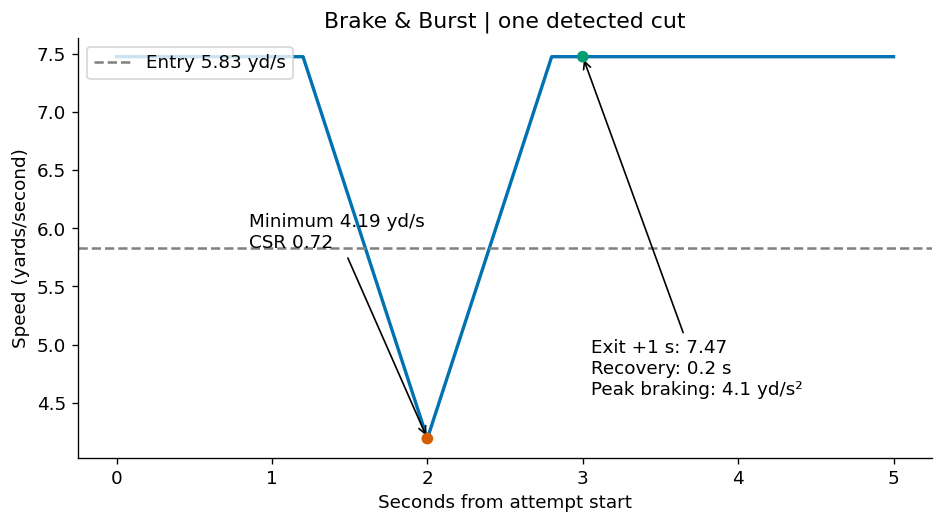

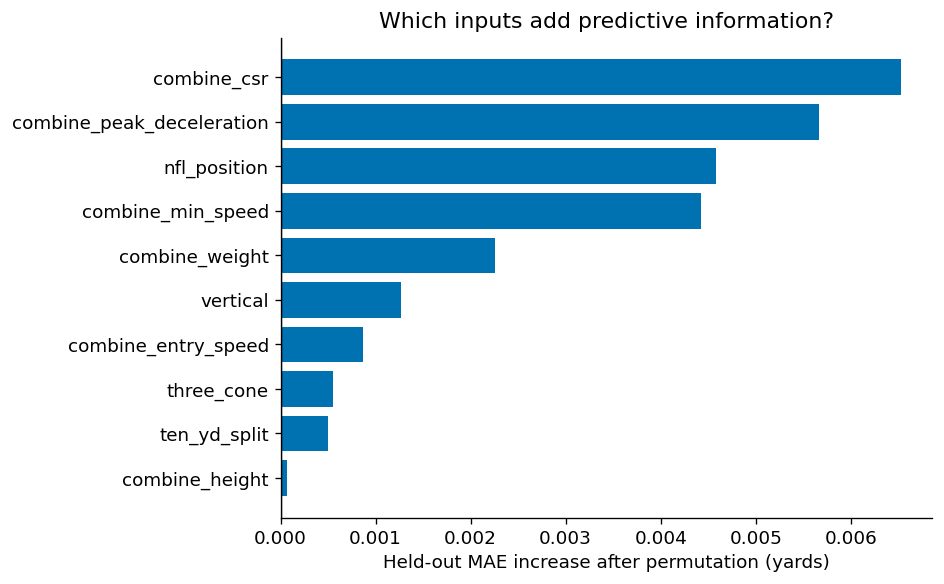

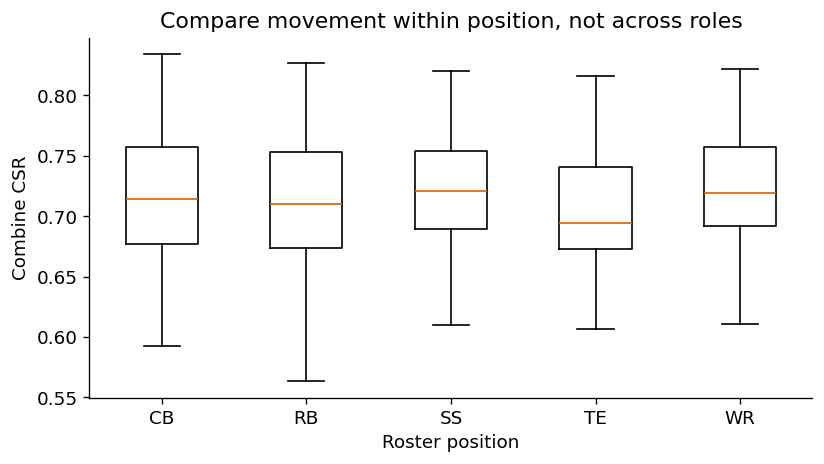

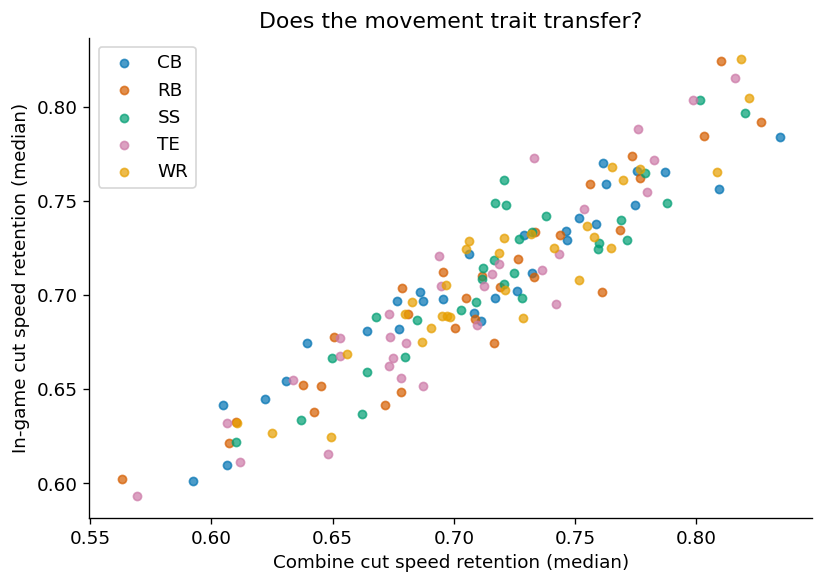

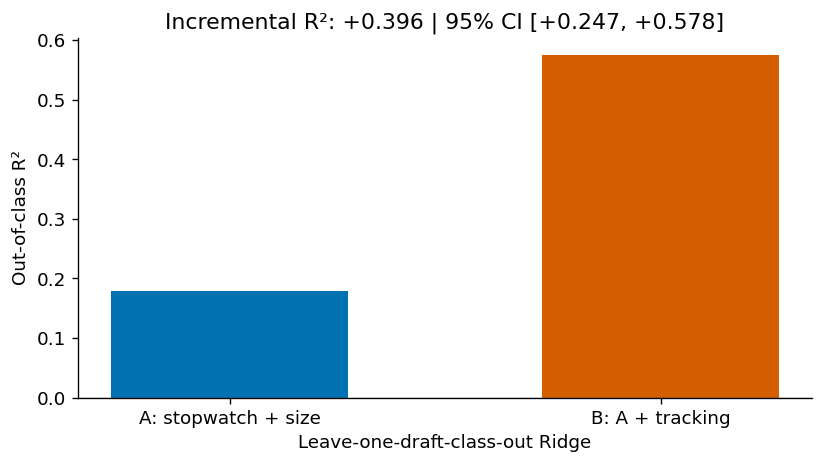

fold        r2  \
validation          family            variant task                         
draft_class         gradient_boosting A       separation   1.0 -0.385629   
                                              starter      1.0       NaN   
                                      A_draft separation   1.0 -0.393160   
                                              starter      1.0       NaN   
                                      B       separation   1.0  0.438729   
                                              starter      1.0       NaN   
                                      B_draft separation   1.0  0.439948   
                                              starter      1.0       NaN   
                    ridge             A       separation   1.0  0.065362   
                                              starter      1.0       NaN   
                                      A_draft separation   1.0  0.075008   
                                              starter      1.0       NaN   
                                      B       separation   1.0  0.496764   
                                              starter      1.0       NaN   
                                      B_draft separation   1.0  0.468934   
                                              starter      1.0       NaN   
repeated_stratified gradient_boosting A       separation   2.5 -0.228349   
                                              starter      2.5       NaN   
                                      A_draft separation   2.5 -0.157033   
                                              starter      2.5       NaN   
                                      B       separation   2.5  0.385829   
                                              starter      2.5       NaN   
                                      B_draft separation   2.5  0.361441   
                                              starter      2.5       NaN   
                    ridge             A       separation   2.5  0.006091   
                                              starter      2.5       NaN   
                                      A_draft separation   2.5  0.090459   
                                              starter      2.5       NaN   
                                      B       separation   2.5  0.450192   
                                              starter      2.5       NaN   
                                      B_draft separation   2.5  0.445543   
                                              starter      2.5       NaN   

                                                          spearman       mae  \
validation          family            variant task                             
draft_class         gradient_boosting A       separation  0.300752  0.184315   
                                              starter          NaN       NaN   
                                      A_draft separation  0.267168  0.193023   
                                              starter          NaN       NaN   
                                      B       separation  0.615539  0.125847   
                                              starter          NaN       NaN   
                                      B_draft separation  0.615539  0.125937   
                                              starter          NaN       NaN   
                    ridge             A       separation  0.445614  0.164724   
                                              starter          NaN       NaN   
                                      A_draft separation  0.498747  0.164135   
                                              starter          NaN       NaN   
                                      B       separation  0.763910  0.122009   
                                              starter          NaN       NaN   
                                      B_draft separation  0.767419  0.125540   
                                              starter          NaN       NaN   
repeated_stratified gradient_boos

In [9]:
from IPython.display import display, Markdown, Image
display(Markdown(Path('REPORT.md').read_text()))
for path in sorted(Path('figures').glob('*.png')):
    display(Image(filename=str(path)))
display(pd.read_csv('outputs/cv_metrics.csv').groupby(['validation','family','variant','task']).mean(numeric_only=True))